# 08M — ทดลองเลือกช่วงอ้างอิงและ Shadow ย้อนหลัง 3 วัน

## อ่านผลนี้เพื่ออะไร

คำถามคือ **การสร้างโปรไฟล์ให้เหมาะกับเครื่องแต่ละตัว ควรคัดช่วงข้อมูลอย่างไร โดยไม่เผลอทำให้ความผิดปกติกลายเป็นค่าปกติใหม่**

เล่มนี้เปรียบเทียบ 4 วิธีบนข้อมูลจริง 9 เครื่อง ทุกโมดูล ผลถูกคำนวณและบันทึกแล้ว ไม่ใช่กราฟตัวอย่าง ไม่มีการเปลี่ยน Active Profile, threshold ที่ใช้งานจริง, MySQL หรือ Server

กราฟใช้ภาษาอังกฤษเพื่อให้ฟอนต์แสดงตรงกันเมื่อย้ายไป Colab; คำอธิบายและการตีความใช้ภาษาไทย งานนี้เป็น retrospective experiment บนข้อมูลที่เคยเปิดดู ไม่ใช่ blind test และไม่มีชุดช่วงปกติที่ช่างยืนยันครบ จึงยังรายงาน accuracy หรือ false-positive rate ไม่ได้

## 1. ข้อมูลมาจากที่ไหน

| เครื่อง | ต้นทาง | Shadow ล่าสุดในงานนี้ |
|---|---|---|
| MX017, MX024, MX080 | ZIP Compressor dynamic logs ที่ตรวจใน Notebook 08K; ไม่ใช้ `_Static.txt` | 28–30 Sep 2026 |
| MX029, MX041, MX057, MX070 | raw Parquet ที่ตรวจใน Notebook 08L; 1 Sep เป็นวันไม่เต็ม | 29–31 Aug 2026 |
| MX118, MX119 | raw Parquet; มีเพียง 17–20 Aug และ 20 Aug เป็นวันไม่เต็ม | 17–19 Aug; ไม่มีอดีตพอสร้าง reference |

ตรวจทั้ง M1–M8; M7 หรือบริบทข้อมูลน้อยยังแสดงเป็น insufficient ไม่ซ่อนออก กราฟเคสอาศัย observed raw seconds ของ MX080/M6 และ MX057/M1 โดยตรวจค่าเฉลี่ยกับ minute cache อีกครั้ง

**Grain:** raw observed seconds → completed 1-minute windows; source time ใช้ Asia/Bangkok ตาม local archive convention ไม่ได้ยืนยัน timezone ของ Server จากการทดลองนี้ ไม่มีการเติมวินาทีที่ขาด

**Gate ที่สืบทอด:** ต้องมี ≥57 unique seconds, ไม่ซ้ำ, gap ≤5 วินาที, ตลอดนาทีมี `Status=Run`, module `On`, Busy=0, SV=Off และ sensor finite. Manual/ChangeValve/SV events ไม่ถูกลบจาก raw evidence แต่ไม่ใช้ fit steady Cold

**รันซ้ำ:** ต้องมี support scripts และ output caches ของ 08K/08L ในโครงสร้างโครงการเดียวกัน; Git ไม่ได้บรรจุ raw telemetry. เปิดบน Colab ให้ upload/mount โฟลเดอร์โปรเจกต์พร้อม cache ส่วนตัว ตั้ง `PROJECT_ROOT` ตามจริง และใช้ dependency versions ใน summary. Notebook ไม่เชื่อม Database

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display
# Colab: set an explicit mounted project directory if needed.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "research/historical_shadow_reference_phase_protocol_v1.json").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "research/historical_shadow_reference_phase_protocol_v1.json").exists():
    raise FileNotFoundError("Set PROJECT_ROOT to the project folder; upload/mount private 08K/08L caches separately.")
sys.path.insert(0, str(PROJECT_ROOT))
from notebooks.support.historical_shadow_reference_phase import run, sha
from notebooks.support import historical_shadow_reference_phase_presentation as viz
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
OUT = PROJECT_ROOT / "notebooks/outputs/historical_shadow_reference_phase_v1"
RUN_EXPERIMENT = False  # True rebuilds all numerical comparisons from private minute caches; no SQL.
if RUN_EXPERIMENT:
    run(OUT)
summary = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))
assert sha(OUT / "shadow_scores.parquet") == summary["score_sha256"]
assert sha(PROJECT_ROOT / "research/historical_shadow_reference_phase_protocol_v1.json") == summary["protocol_sha256"]
t = viz.tables(OUT)
display(pd.DataFrame([{k: summary[k] for k in ["contexts", "matched_contexts", "latest_matched_contexts", "cache_files", "runtime_seconds"]}]))

,contexts,matched_contexts,latest_matched_contexts,cache_files,runtime_seconds
0,88,43,37,229,79.078261


## 2. แบ่งวันอย่างไรไม่ให้ข้อมูลรั่ว

ให้ $D$ เป็นเที่ยงคืนของวันที่ตัดข้อมูลตามเวลาเครื่อง: Shadow = $[D-3d,D)$, Fit = $[D-31d,D-3d)$. ข้อมูลวันนี้ไม่เข้า Shadow และแถวเดียวกันไม่มีทางเข้า Fit กับ Shadow

สำหรับชุดล่าสุด 3 เครื่อง: Fit 31 Aug–27 Sep, Shadow 28–30 Sep, cutoff 1 Oct. อีก 4 เครื่อง cutoff เป็น 1 Sep และ 2 เครื่องข้อมูลน้อย cutoff 20 Aug ตาม inventory รายเครื่อง ไม่ใช่วันที่ล่าสุดของ fleet รวม

QA รอบแรกจับได้ว่าการใช้ fleet cutoff 9 Sep ให้ 6 เครื่องทำให้ Shadow ไม่มีข้อมูล จึงแก้เฉพาะ source cutoff ก่อนสรุป ไม่ปรับ method parameter ตามผล และไม่ใช้ผลรอบนั้นเลือกวิธี; audit อยู่ใน protocol

เคสย้อนหลังแยกออกรายงาน regression: MX080 Shadow 5–7 Sep และ MX057 Shadow 27–29 Aug. ไม่ใช้ผลเคสเลือก parameter, threshold หรือ segment และไม่รวมซ้ำใน headline fleet rate

นี่เป็น **numerical shadow replay** ไม่ได้จำลอง source late-commit, timezone Server, downtime หรือทำทะเบียน Profile/Approval จริง. Historical shadow ทำงานเร็วขึ้นได้ แต่ยังต้องตรวจ production integration แยก

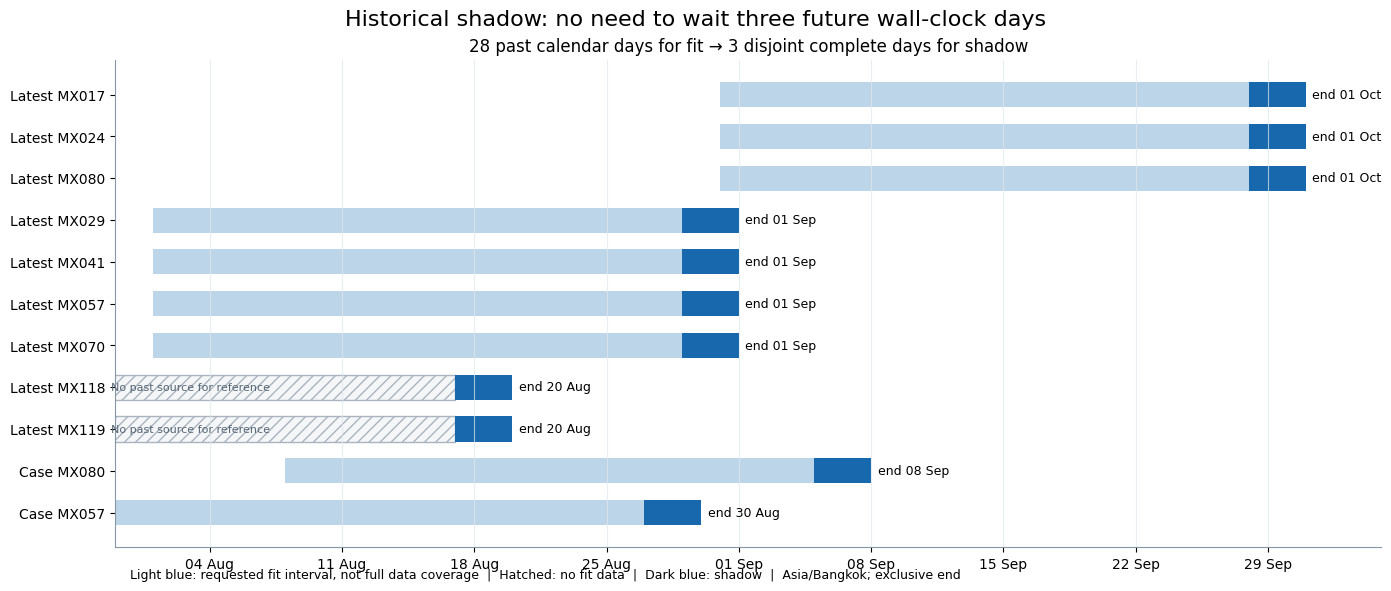

In [2]:
display(viz.periods(OUT))

## 3. สูตรที่ใช้ และสิ่งที่เปลี่ยนในแต่ละวิธี

ทั้ง 4 วิธีใช้ score/persistence เดียวกัน ต่างกันเฉพาะ **แถว Fit ที่เลือก**:

1. State only: ทุกนาทีผ่าน gate ในอดีต
2. Steady reference: เลือกอดีตที่ slope/variation ต่ำต่อเนื่อง
3. Segment reference: แยกอดีตเมื่อ day median กระโดด แล้วเลือก segment มีหลักฐานพอ
4. Segment + steady: ใช้สองข้อร่วมกัน

สำหรับ feature $j$ ในแถว Fit:

$$m_j=\mathrm{median}(x_j),\quad s_j=\max(1.4826\,MAD_j, IQR_j/1.349, f_j)$$
$$z_j(t)=\frac{x_j(t)-m_j}{s_j},\quad A_t=\max_j |z_j(t)|$$

ใช้ feature 9 ตัว: hp1, lp1, hp2, lp2, Valve, TempHi, TempLo, $dp1=hp1-lp1$, $dp2=hp2-lp2$. Floor Valve=1 count, อื่น=.1 source unit. Quarantine แถว Fit ที่ initial $A>8$, fit รอบสองจากแถวที่เหลือ, cut = Q99.5 ของ retained Fit; flag เมื่อ $A_t\ge cut$. Persistent ต้อง flag 3 นาทีที่ติดกันจริง ข้อมูลขาด/นาทีไม่ผ่าน gate ตัด continuity

Scale สูตรนี้สืบทอด **research 08K/08L**, ไม่อ้างว่าเท่ากับ robust-scale implementation/Active Profile จริงทุกตัว การทดลองไม่เปลี่ยน production scale

### ช่วงนิ่งที่เราทดลอง ไม่ใช่ normal label

ใช้ 5 นาที **ที่ผ่านมาเท่านั้น** บนค่าเฉลี่ยนาทีที่มีคุณภาพ:

$$S_j(t)=\left|\mathrm{median}_{0\le a<b<5}\frac{x_j(t-4+b)-x_j(t-4+a)}{b-a}\right|$$
$$V_j(t)=1.4826\,\mathrm{median}_{u=t-4}^{t}|x_j(u)-\mathrm{median}(x_j(t-4:t))|$$

ขีดจำกัดแต่ละ feature = Q90 ของ S/V จากอดีต Fit เท่านั้น พร้อม minimum floors ที่ดูได้ใน code/protocol. ต้องต่ำกว่า limits ทุก feature ต่อเนื่อง 3 windows จึงเรียก `STEADY_CANDIDATE`; เริ่มใหม่หลัง gap/control boundary. สถานะ `CHANGING_OR_SETTLING` ไม่ได้พิสูจน์ normal startup; ไม่มี onset ให้เรียก unknown onset ตามจริง

**สำคัญ:** Phase ไม่ปิด score/flag ช่วงเริ่มทำงาน กราฟนิ่งที่ Hp2=340 ยังตรวจ deviation ได้ ไม่ได้กลายเป็น Normal เพราะ slope ต่ำ

### Segment ช่วยอะไร

เปรียบเทียบ day median ของ hp2/lp2/TempHi/TempLo ระหว่างวันติดกัน หารด้วย median within-day MAD scales (pressure floor .1, temperature .05). Max normalized jump >6 หรือวันขาด จะเริ่ม segment ใหม่. วันต้องมี ≥60 qualified minutes; segment ต้องมี ≥7 วันและ ≥200 นาที เลือก segment มีนาทีมากที่สุด ถ้าเสมอเลือกก่อน ไม่เลือกจากผล Shadow

ถ้ามีหลาย supported segments ต้อง review: ไม่มี service records ที่พิสูจน์ว่าค่าใหม่หลัง manual เป็นค่าปกติ ไม่มี HPO รอบนี้ ตัวเลขทั้งหมดล็อกใน protocol ก่อนรันผล

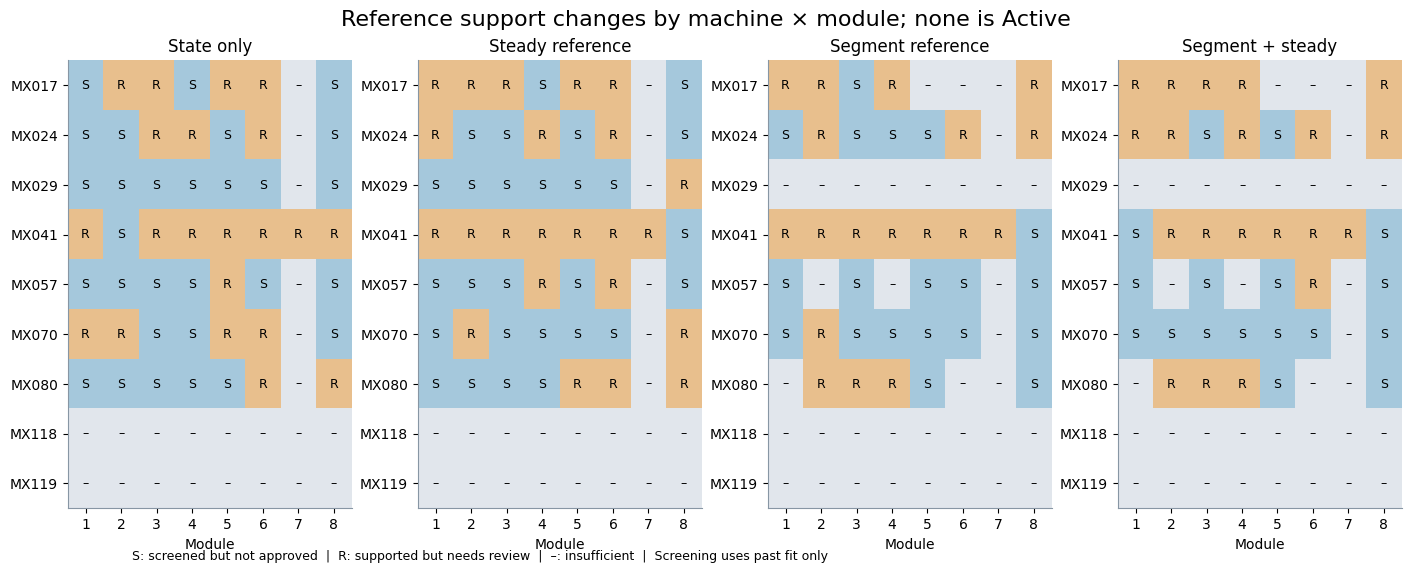

,variant,status,contexts
0,segment_reference,INSUFFICIENT_REFERENCE,45
1,segment_reference,MULTIPLE_REFERENCE_SEGMENTS_REVIEW,13
2,segment_reference,REFERENCE_REVIEW_REQUIRED,7
3,segment_reference,SCREENED_NOT_APPROVED,23
4,segment_steady_reference,INSUFFICIENT_REFERENCE,45
5,segment_steady_reference,MULTIPLE_REFERENCE_SEGMENTS_REVIEW,13
6,segment_steady_reference,REFERENCE_REVIEW_REQUIRED,11
7,segment_steady_reference,SCREENED_NOT_APPROVED,19
8,state_only,INSUFFICIENT_REFERENCE,24
9,state_only,REFERENCE_REVIEW_REQUIRED,29


In [3]:
display(viz.readiness(OUT))
display(t["profiles"].groupby(["variant", "status"]).size().rename("contexts").reset_index())

## 4. ดูการเตือนควบคู่กับ coverage

กราฟซ้ายเปรียบเทียบนาทีเดียวกันเฉพาะบริบทที่ทั้ง 4 วิธีมี reference พอ. กราฟขวาแสดงทุกบริบทล่าสุด: สีเทาคือ qualified แต่ไม่มี reference รองรับ ไม่ใช่ Normal

โปรไฟล์กว้างจากการปนหลายระดับอาจทำให้เตือนน้อย ขณะที่คัด reference ให้แคบอาจเตือนมากขึ้น ทั้งสองกรณีต้องดูเหตุการณ์จริงและ negative periods ที่ยืนยันก่อนตัดสินว่าดีกว่า. การเพิ่ม/ลด flag rate ไม่ใช่ accuracy

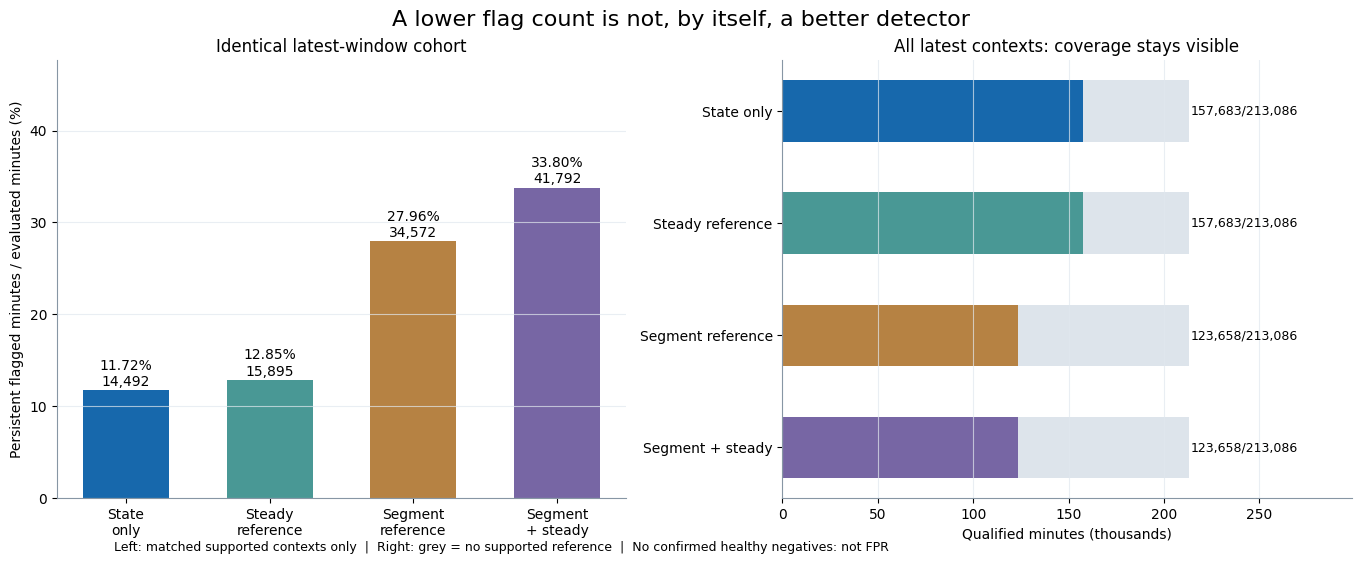

,variant,evaluated_minutes,persistent_minutes,openings,persistent_percent
0,segment_reference,123658,34572,773,27.958
1,segment_steady_reference,123658,41792,1027,33.796
2,state_only,123658,14492,334,11.719
3,steady_reference,123658,15895,599,12.854


In [4]:
display(viz.burden(OUT))
display(t["matched"].round(3))

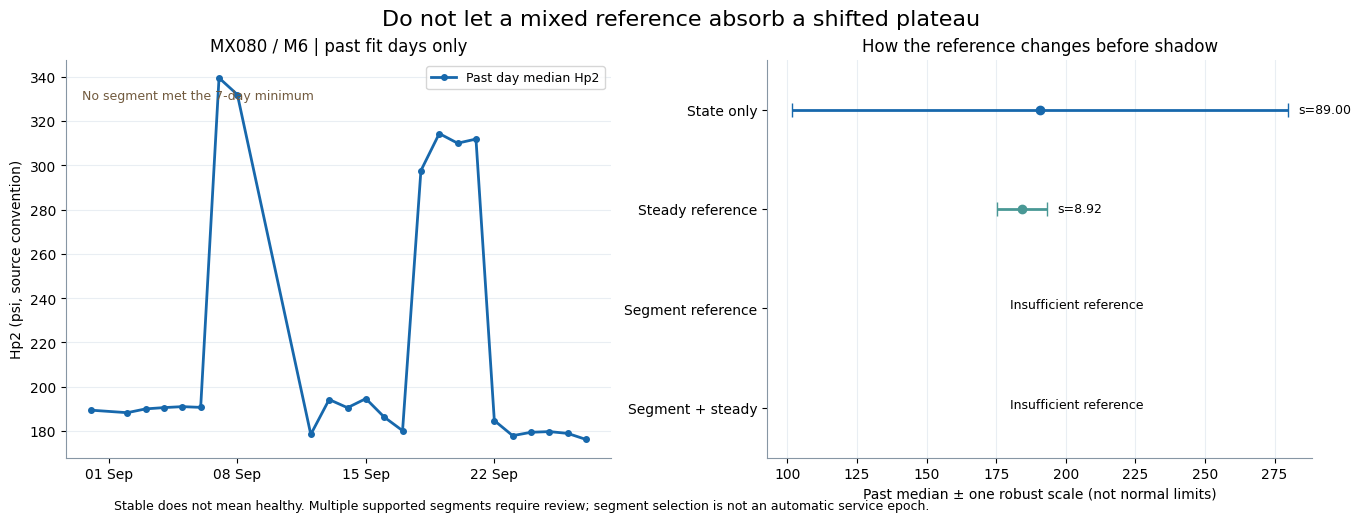

In [5]:
display(viz.baseline_example(OUT))

## 5. แยกบริบทของแถบเตือน

แสดง persistent minutes ที่อยู่ในช่วง stable/changing/history insufficient โดยยังเก็บ score ทั้งหมด สัดส่วน onset observed มีอยู่ใน `shadow_burden.csv`; ไม่ตีช่วงแรกของไฟล์เป็น compressor restart

ยังไม่มี trajectory envelope ของ healthy startups ที่ช่างทบทวนครบ การทดลองนี้ทดสอบ causal steady selector ไม่ใช่ trained startup-normal model. ถ้าจะลด normal-startup alarm ต้องแยก observed start / Cold entry / post-manual และ validate หลายรอบก่อน

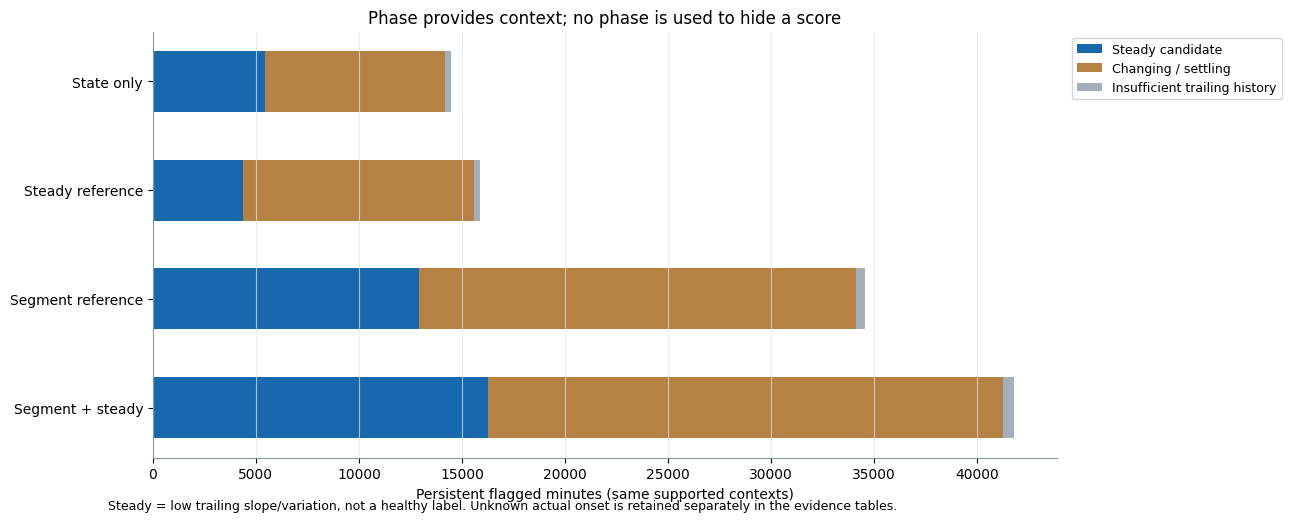

In [6]:
display(viz.phase_workload(OUT))

### หลายรอบเริ่มทำงานหน้าตาเหมือนกันหรือไม่

กราฟต่อไปใช้ raw seconds จาก observed `Run` transitions ของ 3 เครื่อง/M6 ในช่วง Fit 31 Aug–27 Sep เท่านั้น แสดงต้นรอบตามเวลา ไม่เลือกเพราะกราฟดูสวย. เส้นละหนึ่งรอบ; จำกัดภาพที่ 18 รอบจาก archive ที่ sample ไว้ มีตารางจำนวนรอบ/วันประกอบ

เส้นที่นิ่งอยู่ระดับสูงยังไม่ถูกเรียก healthy และไม่รวม median เป็น normal envelope เพราะไม่มี healthy-cycle review. กราฟนี้ชี้ว่า initial conditions และการตอบสนองไม่เหมือนกัน แต่ไม่ได้พิสูจน์ว่าแต่ละเส้นมี fault. ถ้ารอบมีน้อย ให้แสดงตามจริง ไม่ยืดให้ครบจำนวน

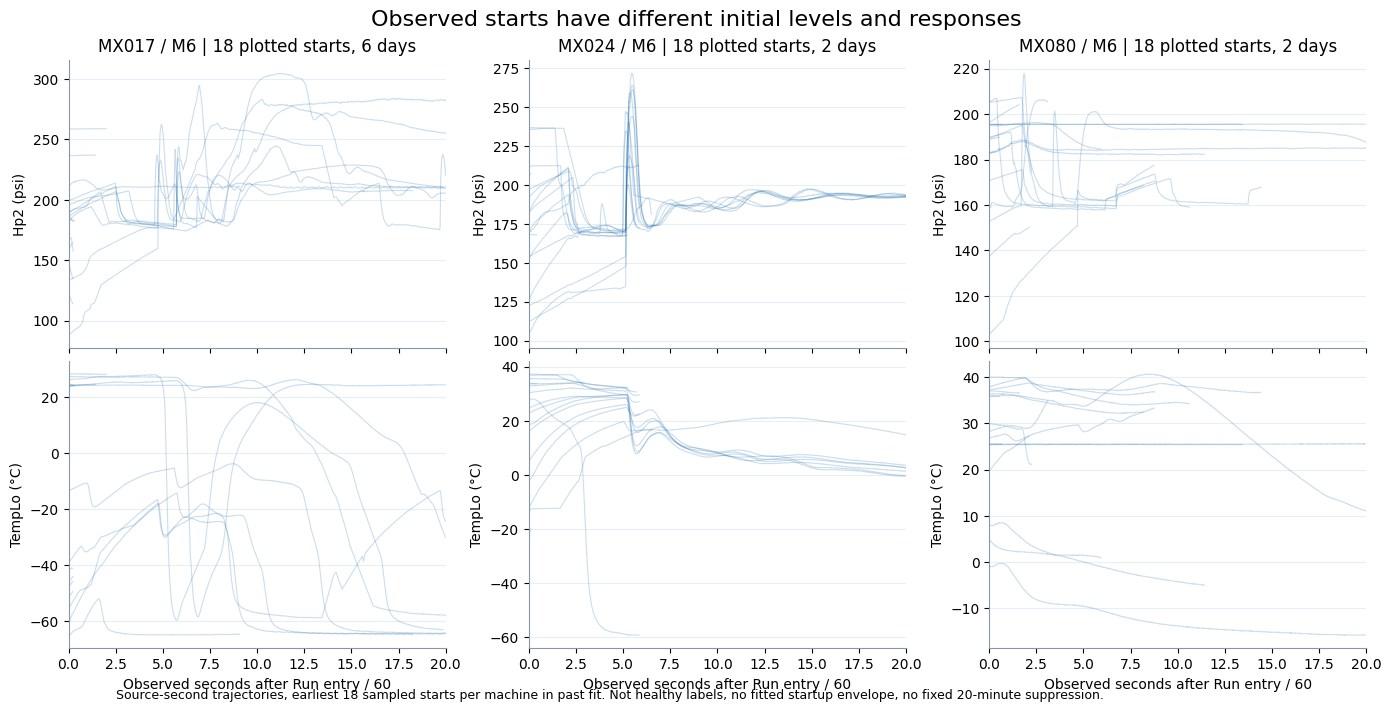

,machine,module,available_sampled_run_starts,plotted_starts,plotted_days,fit_period_start,fit_period_end_exclusive,healthy_labels
0,017,6,40,18,6,2026-08-31,2026-09-28,False
1,024,6,54,18,2,2026-08-31,2026-09-28,False
2,080,6,44,18,2,2026-08-31,2026-09-28,False


In [7]:
display(viz.observed_starts(OUT))
display(pd.read_csv(OUT / "plotted_observed_start_support.csv", dtype={"machine":str}))

## 6. ตรวจว่าเคสที่รู้แล้วไม่หาย

MX080/M6 ช่วง 7 Sep และ MX057/M1 ช่วง 29 Aug เป็น owner-confirmed **behavioral anomaly** ไม่ใช่ cause label. Coverage นับ persistent/qualified case minutes รวมกรณี unsupported ใน denominator. First persistent เป็นเวลา minute decision ภายใต้ replay ไม่ใช่ real ingestion latency

กราฟ raw seconds แยกหน่วยและมีแถบ decision ด้านล่าง ไม่ย้อม pressure แดงเพราะ temperature contributor. การเปลี่ยน Valve/Busy เป็น control context ไม่ใช่ confirmed refill หรือ fault

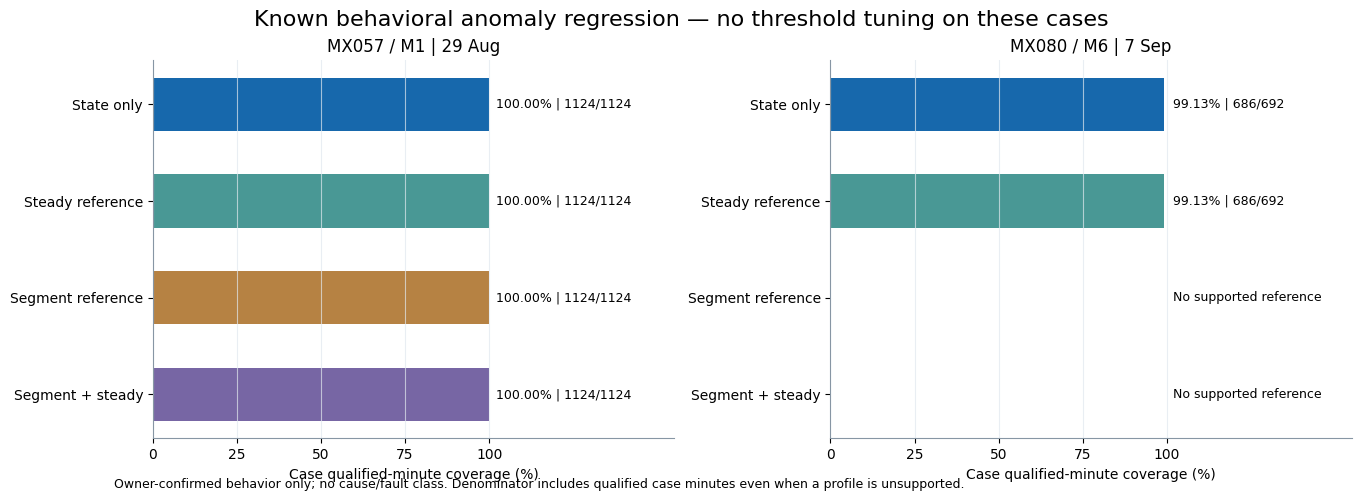

,experiment,machine,module,variant,case_start,case_end,qualified_minutes,evaluated_minutes,persistent_minutes,persistent_coverage_percent,first_persistent,changing_hits,steady_hits,reference_status
0,case_mx080,080,6,state_only,2026-09-07 12:24,2026-09-08,692,692,686,99.133,2026-09-07 12:24:00,406,273,REFERENCE_REVIEW_REQUIRED
1,case_mx080,080,6,steady_reference,2026-09-07 12:24,2026-09-08,692,692,686,99.133,2026-09-07 12:24:00,406,273,SCREENED_NOT_APPROVED
2,case_mx080,080,6,segment_reference,2026-09-07 12:24,2026-09-08,692,0,0,0.000,NaN,0,0,INSUFFICIENT_REFERENCE
3,case_mx080,080,6,segment_steady_reference,2026-09-07 12:24,2026-09-08,692,0,0,0.000,NaN,0,0,INSUFFICIENT_REFERENCE
4,case_mx057,057,1,state_only,2026-08-29 04:06,2026-08-29 22:51,1124,1124,1124,100.000,2026-08-29 04:06:00,978,144,SCREENED_NOT_APPROVED
5,case_mx057,057,1,steady_reference,2026-08-29 04:06,2026-08-29 22:51,1124,1124,1124,100.000,2026-08-29 04:06:00,978,144,SCREENED_NOT_APPROVED
6,case_mx057,057,1,segment_reference,2026-08-29 04:06,2026-08-29 22:51,1124,1124,1124,100.000,2026-08-29 04:06:00,978,144,SCREENED_NOT_APPROVED
7,case_mx057,057,1,segment_steady_reference,2026-08-29 04:06,2026-08-29 22:51,1124,1124,1124,100.000,2026-08-29 04:06:00,978,144,SCREENED_NOT_APPROVED


In [8]:
display(viz.case_coverage(OUT))
display(t["cases"].round(3))

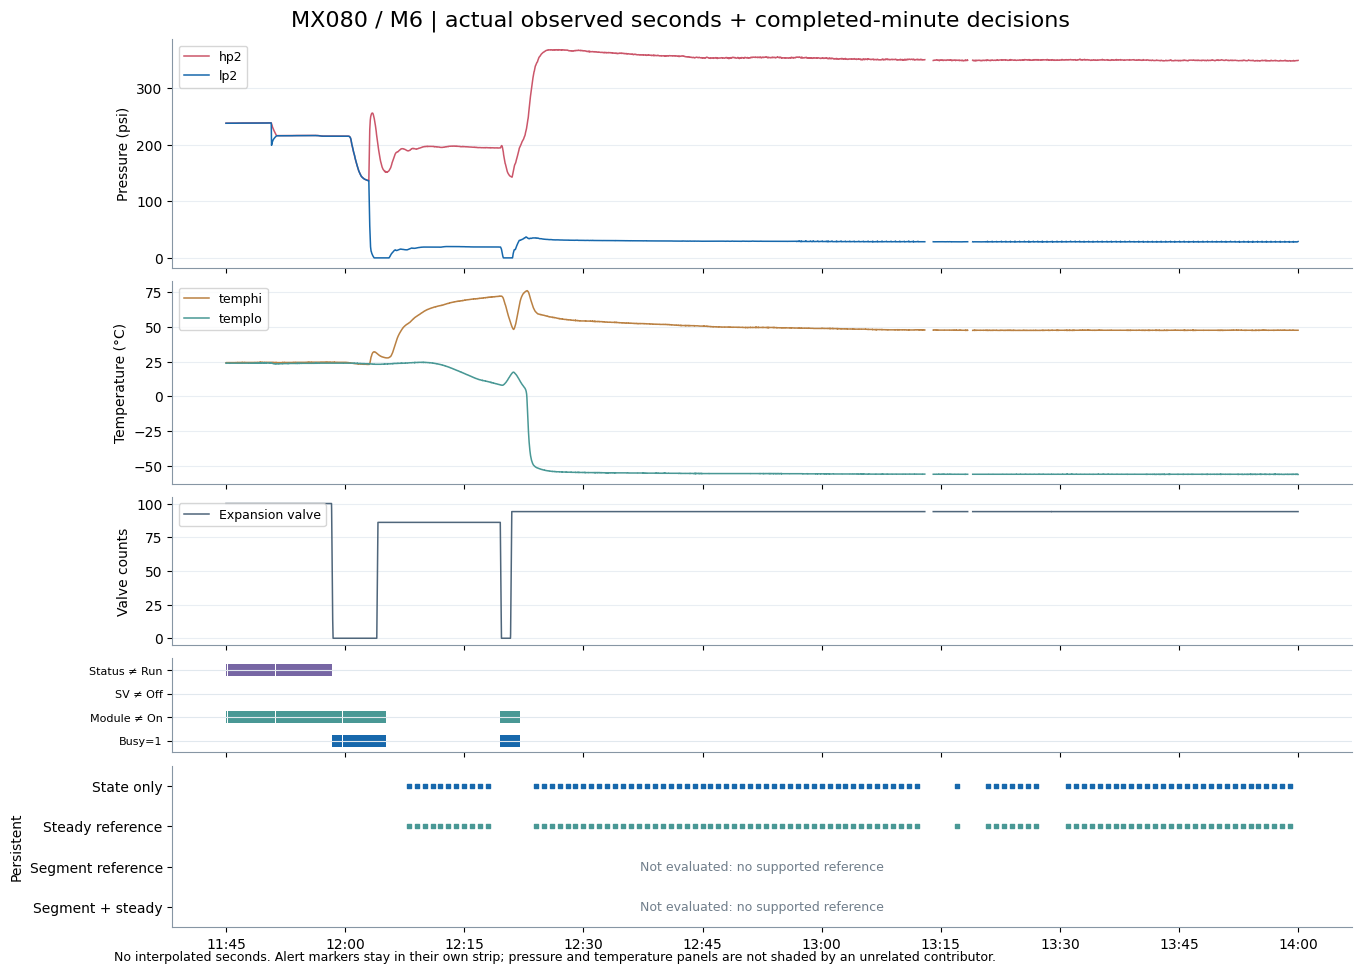

In [9]:
display(viz.raw_case_panel("080", OUT))

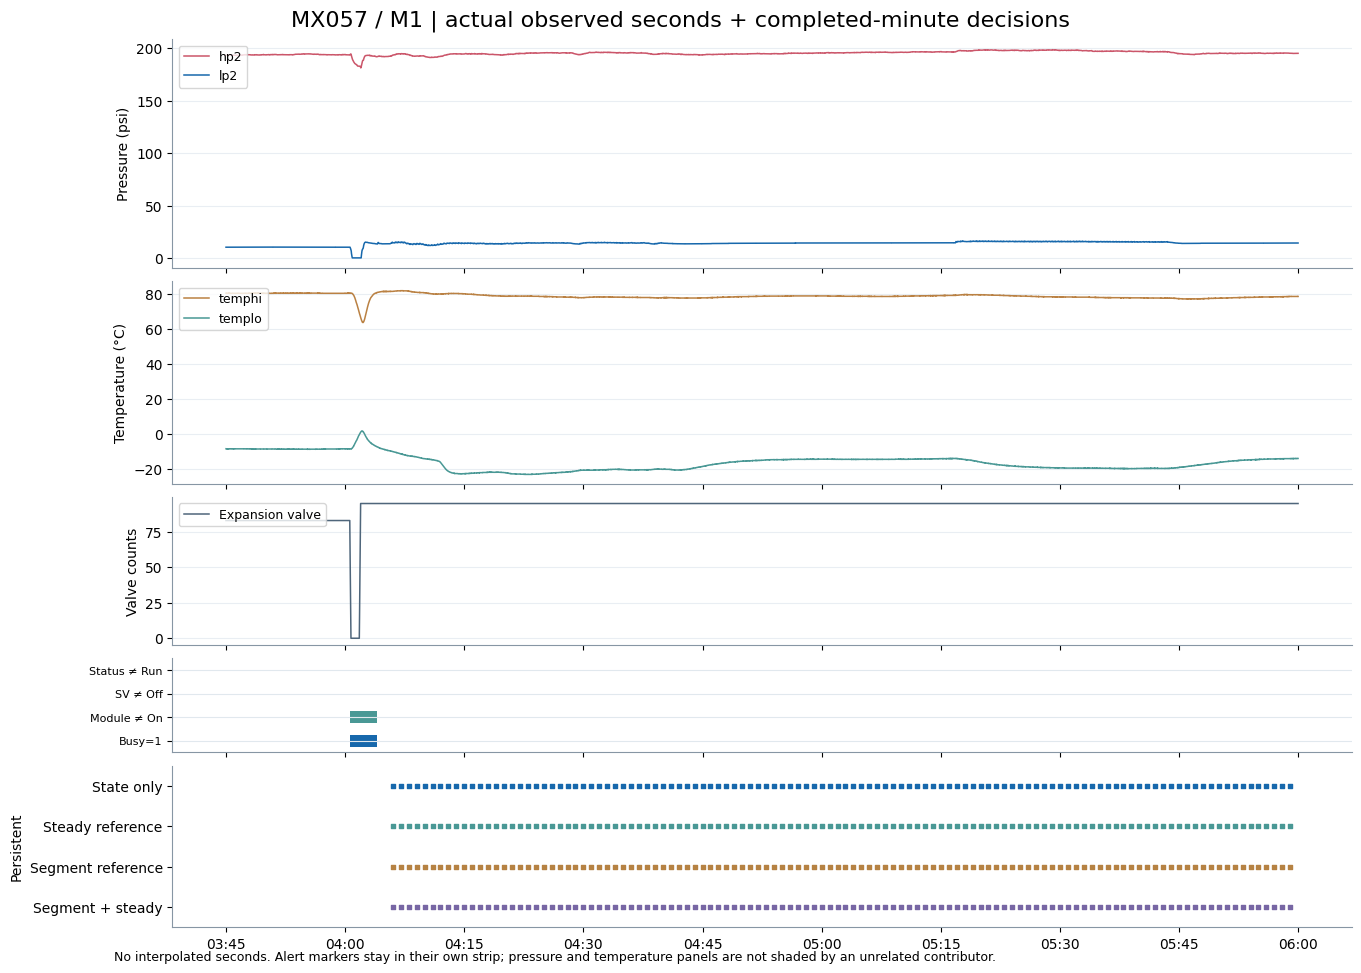

In [10]:
display(viz.raw_case_panel("057", OUT))

## 7. สรุปสำหรับตัดสินใจ

อย่าเลือกวิธีจากจำนวนแถบแดงเพียงอย่างเดียว อ่านพร้อมกัน 4 อย่าง: จำนวน reference ที่มีหลักฐานพอ, scale/ระดับที่ใช้, coverage ของทุกบริบท และเคสที่ต้องไม่หาย

**ผลจริงของรอบนี้:** บน 37 บริบท/123,658 นาทีที่ทั้งสี่วิธีรองรับ วิธีเดิมเตือน 11.72%, steady 12.85%, segment 27.96%, segment+steady 33.80%. ตัวเลขนี้เป็นภาระการตรวจ ไม่ใช่ false-positive rate. Segment ไม่ได้ชนะและมี coverage ต่ำกว่า; MX080/M6 ไม่มี segment ผ่านขั้นต่ำ

State-only และ steady ยังครอบคลุมเคส MX080/M6 686/692 นาที (99.13%) และ MX057/M1 1,124/1,124 นาที (100%). เป็น case regression ไม่ใช่ accuracy. ก่อน Hp2 กระโดด ช่วง 11:45–12:20 ของ MX080 ทั้งสองวิธียัง flag 11/13 qualified minutes โดย dominant เป็น Lp1 จาก reference ใหม่ จึงยังแก้ startup specificity ไม่ได้ และไม่เท่ากับ contributor ของ Active Profile เดิม

**สิ่งที่ใช้ต่อได้ทันทีในแนวทางระบบ:** manual start ของงาน calibration, historical complete-day split ที่แยก fit/shadow, แสดง selected reference period + omitted days + phase evidence ใน approval report, เก็บ score ช่วงเปลี่ยนผ่าน ไม่ลบหลักฐาน. ทั้งหมดเป็นข้อเสนอ integration; code runtime ยังไม่ได้เปลี่ยน

**สิ่งที่ยังไม่ควรเปิดอัตโนมัติจากงานนี้:** เปลี่ยน Active ตาม segment ล่าสุด, suppress startup ตามเวลา, approve จาก low flag rate, หรือบอก leak/cause. ไม่มีการ train ML ใหม่ เพราะรอบนี้กำลังปรับคุณภาพ reference ที่ primary algorithm ใช้ ไม่ใช่เพิ่ม classifier

ดูผล/คำแนะนำจริงพร้อมข้อจำกัดใน `deployment/HISTORICAL_SHADOW_REFERENCE_PHASE_EXPERIMENT_20261001.md` และเปิด CSV เพื่อดูทุก machine × module โดยไม่รวมข้อมูลน้อยกับ Normal

### QA และขอบเขต

Tests ตรวจ prefix causality, train-only limits/fit/segment, gap reset, minimum days, disjoint calendar split, persistence และ stable abnormal plateau. Notebook รันทุก cell และตรวจ raw-minute parity อีกครั้ง. ข้อมูลต้นทาง/Active/DB/Serverไม่เปลี่ยน; ยังไม่มี production approval. Artifact hash ทำให้ตรวจได้ว่าผลตรงกับ input/protocol ใด

In [11]:
receipt = json.loads((OUT / "input_receipt.json").read_text(encoding="utf-8"))
missing = [p for p in receipt if not (PROJECT_ROOT / p).exists()]
if missing:
    print(f"{len(missing)} private input caches not mounted; figures above use saved experiment outputs.")
else:
    assert all(sha(PROJECT_ROOT / p) == info["sha256"] for p, info in receipt.items())
    print(f"Verified SHA256 for {len(receipt)} private minute inputs.")
display(pd.DataFrame({"Boundary":["Runtime changed", "Active changed", "DB writes", "Server access"],
                      "Result":[summary[k] for k in ["runtime_changed", "active_changed", "db_writes", "server_access"]]}))

Verified SHA256 for 229 private minute inputs.


,Boundary,Result
0,Runtime changed,False
1,Active changed,False
2,DB writes,False
3,Server access,False
